# 05b — Difficulty: TF-IDF dengan Angka (3 Model)

**Latar belakang:** Notebook 07 menunjukkan bahwa mempertahankan angka (batasan seperti `10^5`) menaikkan Macro-F1 difficulty pada TF-IDF × LogReg (+0,044 CV, konsisten di 5/5 fold). Tabel utama di Notebook 05 memakai TF-IDF **tanpa** angka, sehingga perbandingannya dengan transformer (yang melihat angka) tidak setara. Notebook ini menambahkan representasi **`tfidf_digits`** untuk **ketiga model** (LogReg, Random Forest, MLP) dengan protokol yang **identik** dengan Notebook 05.

**Input (Add Data):** `data_clean.csv`, `labels.csv`, `split.csv`
**Input opsional (untuk tabel gabungan):** *output* Notebook 05 (`difficulty_results.csv` dan folder `difficulty_proba/`). Di Kaggle: Add Data → Notebook Output Files → pilih notebook 05-mu.

**Output:** `results/difficulty_results_tfidf_digits.csv`, `results/difficulty_proba/tfidf_digits_*`, dan tabel gabungan di `tables/`.

## Yang sama dengan Notebook 05 (agar adil)
Split dan fold dari `split.csv`; test set dipakai sekali; ruang pencarian hyperparameter dan seed sama persis; TF-IDF di-fit hanya pada data latih tiap fold; pembobotan kelas sama; metrik sama.

## Satu-satunya perbedaan
Teks masukan = `text_clean_digits` (kata + angka). `TfidfVectorizer` memakai `token_pattern=r'(?u)\b\w+\b'` agar token angka satu karakter (misalnya `5` dari `10^5`) tidak dibuang.

**Estimasi waktu:** 15-25 menit (Random Forest yang paling lama). Hasil disimpan tiap model; sel utama bisa dijalankan ulang untuk melanjutkan.

## 1. Import & Konfigurasi

In [1]:
import glob
import itertools
import json
import os
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from scipy import sparse
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_recall_fscore_support)

warnings.filterwarnings('ignore')

QUICK = False        # True = uji cepat. Untuk hasil paper WAJIB False.
SEED = 42
TFIDF_MAX = 10000
N_ITER_RF = 2 if QUICK else 6
REP = 'tfidf_digits'
MODELS = ['logreg', 'rf', 'mlp']
CLASS_NAMES = ['Easy', 'Medium', 'Hard']
N_BOOT = 1000

ON_KAGGLE = os.path.exists('/kaggle/input')
OUT_DIR = '/kaggle/working' if ON_KAGGLE else '.'
RES_DIR = os.path.join(OUT_DIR, 'results')
PROBA_DIR = os.path.join(RES_DIR, 'difficulty_proba')
TAB_DIR = os.path.join(OUT_DIR, 'tables')
FIG_DIR = os.path.join(OUT_DIR, 'figures')
for d in (RES_DIR, PROBA_DIR, TAB_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', DEVICE, '| QUICK:', QUICK)


def find_optional(pattern_name, subdir=None):
    # Cari file di folder kerja atau di input Kaggle; None bila tidak ada
    cands = [pattern_name]
    if subdir:
        cands += [os.path.join(subdir, pattern_name), os.path.join('results', subdir, pattern_name)]
    for p in cands:
        if os.path.exists(p):
            return p
    pat = f'/kaggle/input/**/{subdir}/{pattern_name}' if subdir else f'/kaggle/input/**/{pattern_name}'
    hits = glob.glob(pat, recursive=True)
    return hits[0] if hits else None


def find_file(name):
    p = find_optional(name)
    assert p, f'{name} tidak ditemukan (tambahkan Kaggle Dataset-nya)'
    return p

Device: cuda | QUICK: False


## 2. Load Data

In [2]:
df = pd.read_csv(find_file('data_clean.csv'))
labels = pd.read_csv(find_file('labels.csv'))
split = pd.read_csv(find_file('split.csv'))
assert (df['id'].values == labels['id'].values).all() and (df['id'].values == split['id'].values).all()

y = labels['difficulty_id'].values.astype(int)          # Easy=0, Medium=1, Hard=2
N, K = len(y), 3
texts = df['text_clean_digits'].fillna('').values

is_train = (split['set'] == 'train').values
train_idx = np.where(is_train)[0]
test_idx = np.where(~is_train)[0]
fold = split['fold'].values
folds = [(train_idx[fold[train_idx] != k], train_idx[fold[train_idx] == k]) for k in range(5)]
yte = y[test_idx]
assert set(train_idx).isdisjoint(set(test_idx))
print(f'N={N}  train={len(train_idx)}  test={len(test_idx)}')
print('Contoh teks:', texts[0][:150])

N=3256  train=2605  test=651
Contoh teks: array integers nums integer target indices two numbers add target may assume would exactly one solution may use element twice answer order 1 nums 2 7 


## 3. Metrik dan Fitur

In [3]:
def full_metrics(yt, yp):
    p, r, f, _ = precision_recall_fscore_support(yt, yp, average='macro', zero_division=0)
    return {'accuracy': accuracy_score(yt, yp), 'macro_precision': p, 'macro_recall': r, 'macro_f1': f,
            'weighted_f1': f1_score(yt, yp, average='weighted', zero_division=0)}


def macro_f1(yt, yp):
    return f1_score(yt, yp, average='macro', zero_division=0)


_cache = {}


def get_xy(tr, ev, key):
    if key not in _cache:
        vec = TfidfVectorizer(max_features=TFIDF_MAX, ngram_range=(1, 2), min_df=2,
                              sublinear_tf=True, token_pattern=r'(?u)\b\w+\b')
        Xtr = vec.fit_transform(texts[tr])
        Xev = vec.transform(texts[ev])
        _cache[key] = (Xtr, Xev)
    return _cache[key]

## 4. Model dan Ruang Pencarian (identik dengan Notebook 05)

Fungsi `fit_*` dan `make_grids()` disalin persis dari Notebook 05, termasuk seed yang menentukan 6 konfigurasi Random Forest.

In [4]:
def fit_logreg(Xtr, ytr, Xev, p):
    clf = LogisticRegression(C=p['C'], class_weight='balanced', max_iter=2000)
    clf.fit(Xtr, ytr)
    return clf.predict_proba(Xev)


def fit_rf(Xtr, ytr, Xev, p):
    rf = RandomForestClassifier(
        n_estimators=p['n_estimators'], max_depth=p['max_depth'],
        min_samples_leaf=p['min_samples_leaf'], max_features=p['max_features'],
        class_weight='balanced_subsample', n_jobs=-1, random_state=SEED)
    rf.fit(Xtr, ytr)
    return rf.predict_proba(Xev)


def _dense(X):
    return X.toarray() if sparse.issparse(X) else np.asarray(X)


def fit_mlp(Xtr, ytr, Xev, p):
    torch.manual_seed(SEED)
    np.random.seed(SEED)
    Xtr_t = torch.tensor(_dense(Xtr), dtype=torch.float32, device=DEVICE)
    Xev_t = torch.tensor(_dense(Xev), dtype=torch.float32, device=DEVICE)
    ytr_t = torch.tensor(ytr, dtype=torch.long, device=DEVICE)

    model = nn.Sequential(
        nn.Linear(Xtr_t.shape[1], 256), nn.BatchNorm1d(256), nn.ReLU(),
        nn.Dropout(0.3), nn.Linear(256, K)).to(DEVICE)

    counts = np.bincount(ytr, minlength=K)
    cw = torch.tensor(len(ytr) / (K * np.maximum(counts, 1)), dtype=torch.float32, device=DEVICE)
    loss_fn = nn.CrossEntropyLoss(weight=cw)
    opt = torch.optim.AdamW(model.parameters(), lr=p['lr'], weight_decay=p['weight_decay'])

    n, bs = Xtr_t.shape[0], 64
    g = torch.Generator(device='cpu').manual_seed(SEED)
    for _ in range(p['epochs']):
        model.train()
        perm = torch.randperm(n, generator=g)
        for s in range(0, n, bs):
            b = perm[s:s + bs].to(DEVICE)
            if len(b) < 2:
                continue
            opt.zero_grad()
            loss_fn(model(Xtr_t[b]), ytr_t[b]).backward()
            opt.step()

    model.eval()
    with torch.no_grad():
        logits = torch.cat([model(Xev_t[s:s + 512]) for s in range(0, Xev_t.shape[0], 512)])
    return torch.softmax(logits, dim=1).cpu().numpy()


FIT = {'logreg': fit_logreg, 'rf': fit_rf, 'mlp': fit_mlp}


def make_grids():
    if QUICK:
        return {
            'logreg': [{'C': 1.0}],
            'rf': [{'n_estimators': 50, 'max_depth': 20, 'min_samples_leaf': 1, 'max_features': 'sqrt'}],
            'mlp': [{'lr': 1e-3, 'weight_decay': 1e-2, 'epochs': 5}],
        }
    rf_space = list(itertools.product([200, 400], [None, 20, 40], [1, 2], ['sqrt', 0.2]))
    r = np.random.default_rng(SEED)
    pick = r.choice(len(rf_space), size=N_ITER_RF, replace=False)
    return {
        'logreg': [{'C': c} for c in [0.1, 1.0, 10.0]],
        'rf': [dict(zip(['n_estimators', 'max_depth', 'min_samples_leaf', 'max_features'], rf_space[i]))
               for i in pick],
        'mlp': [{'lr': lr, 'weight_decay': 1e-2, 'epochs': e} for lr in [1e-3, 3e-4] for e in [30, 60]],
    }


GRIDS = make_grids()
print({m: len(g) for m, g in GRIDS.items()}, 'konfigurasi per model')

{'logreg': 3, 'rf': 6, 'mlp': 4} konfigurasi per model


## 5. Prosedur Satu Kombinasi (identik dengan Notebook 05)

Prediksi OOF di 5 fold latih → pilih konfigurasi dengan Macro-F1 OOF tertinggi → refit di seluruh data latih → evaluasi test set sekali.

In [5]:
def run_combo(model):
    fit, grid = FIT[model], GRIDS[model]
    t0 = time.time()
    best = None

    for p in grid:
        oof = np.zeros((N, K))
        for k, (tr, ev) in enumerate(folds):
            Xtr, Xev = get_xy(tr, ev, k)
            oof[ev] = fit(Xtr, y[tr], Xev, p)
        score = macro_f1(y[train_idx], oof[train_idx].argmax(axis=1))
        if best is None or score > best['score']:
            best = {'p': p, 'score': score, 'oof': oof.copy()}

    fold_f1 = [macro_f1(y[ev], best['oof'][ev].argmax(axis=1)) for _, ev in folds]
    fold_acc = [accuracy_score(y[ev], best['oof'][ev].argmax(axis=1)) for _, ev in folds]

    Xtr, Xte = get_xy(train_idx, test_idx, 'full')
    P_test = fit(Xtr, y[train_idx], Xte, best['p'])
    m = full_metrics(yte, P_test.argmax(axis=1))

    np.save(os.path.join(PROBA_DIR, f'{REP}_{model}_test.npy'), P_test)
    np.save(os.path.join(PROBA_DIR, f'{REP}_{model}_oof.npy'), best['oof'][train_idx])

    return {
        'rep': REP, 'model': model, 'best_params': json.dumps(best['p']),
        'cv_macro_f1_oof': round(best['score'], 4),
        'cv_macro_f1_mean': round(float(np.mean(fold_f1)), 4),
        'cv_macro_f1_std': round(float(np.std(fold_f1)), 4),
        'cv_accuracy_mean': round(float(np.mean(fold_acc)), 4),
        'test_accuracy': round(m['accuracy'], 4),
        'test_macro_precision': round(m['macro_precision'], 4),
        'test_macro_recall': round(m['macro_recall'], 4),
        'test_macro_f1': round(m['macro_f1'], 4),
        'test_weighted_f1': round(m['weighted_f1'], 4),
        'seconds': round(time.time() - t0, 1),
    }

## 6. Jalankan (3 model)

In [6]:
RES_PATH = os.path.join(RES_DIR, 'difficulty_results_tfidf_digits.csv')
rows, done = [], set()
if os.path.exists(RES_PATH):
    prev_df = pd.read_csv(RES_PATH)
    rows = prev_df.to_dict('records')
    done = set(prev_df['model'])
    print('Melanjutkan, sudah selesai:', sorted(done))

for model in MODELS:
    if model in done:
        continue
    row = run_combo(model)
    rows.append(row)
    pd.DataFrame(rows).to_csv(RES_PATH, index=False)
    print(f"[{REP} x {model:6s}] CV macro-F1={row['cv_macro_f1_mean']:.4f}±{row['cv_macro_f1_std']:.4f} "
          f"| test macro-F1={row['test_macro_f1']:.4f} acc={row['test_accuracy']:.4f} | {row['seconds']}s")

new = pd.read_csv(RES_PATH)
new

[tfidf_digits x logreg] CV macro-F1=0.5441±0.0123 | test macro-F1=0.5395 acc=0.5484 | 29.9s
[tfidf_digits x rf    ] CV macro-F1=0.5440±0.0063 | test macro-F1=0.5423 acc=0.6022 | 395.9s
[tfidf_digits x mlp   ] CV macro-F1=0.5249±0.0118 | test macro-F1=0.5338 acc=0.5484 | 82.7s


,rep,model,best_params,cv_macro_f1_oof,cv_macro_f1_mean,cv_macro_f1_std,cv_accuracy_mean,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,test_weighted_f1,seconds
0,tfidf_digits,logreg,"{""C"": 1.0}",0.5444,0.5441,0.0123,0.5516,0.5484,0.5341,0.5478,0.5395,0.5499,29.9
1,tfidf_digits,rf,"{""n_estimators"": 400, ""max_depth"": 40, ""min_sa...",0.5441,0.5440,0.0063,0.6084,0.6022,0.5976,0.5412,0.5423,0.5784,395.9
2,tfidf_digits,mlp,"{""lr"": 0.0003, ""weight_decay"": 0.01, ""epochs"":...",0.5255,0.5249,0.0118,0.5394,0.5484,0.5304,0.5382,0.5338,0.5478,82.7


## 7. Tabel Gabungan dengan Notebook 05

Sel ini memakai `difficulty_results.csv` dari Notebook 05 **jika ditambahkan sebagai input**. Jika tidak ada, sel dilewati (hasil di atas tetap berlaku). Tabel gabungan memuat 18 kombinasi, dan "terbaik menurut CV" dihitung ulang di antara semuanya.

In [7]:
main_path = find_optional('difficulty_results.csv')
if main_path is None:
    print('difficulty_results.csv (Notebook 05) tidak ditemukan. Tambahkan output Notebook 05 sebagai input')
    print('untuk membuat tabel gabungan. Hasil tfidf_digits di atas sudah lengkap.')
    combined = new.copy()
else:
    main = pd.read_csv(main_path)
    combined = pd.concat([main, new], ignore_index=True)
    print('Notebook 05 dimuat dari:', main_path, '| baris:', len(main))

combined.to_csv(os.path.join(TAB_DIR, 'difficulty_results_combined.csv'), index=False)
order = ['tfidf', 'tfidf_digits', 'glove', 'fasttext', 'sbert', 'codebert']
for metric in ['cv_macro_f1_mean', 'test_macro_f1', 'test_accuracy']:
    pv = combined.pivot(index='rep', columns='model', values=metric)
    pv = pv.reindex([r for r in order if r in pv.index])[MODELS]
    pv.to_csv(os.path.join(TAB_DIR, f'difficulty_combined_pivot_{metric}.csv'))
    print(metric)
    print(pv.round(4).to_string())
    print()

best_all = combined.sort_values('cv_macro_f1_mean', ascending=False).iloc[0]
print(f"Terbaik menurut CV (semua kombinasi): {best_all['rep']} x {best_all['model']} "
      f"(CV {best_all['cv_macro_f1_mean']}, test {best_all['test_macro_f1']})")

Notebook 05 dimuat dari: /kaggle/input/notebooks/trioswnn/05-modeling-difficulty/results/difficulty_results.csv | baris: 15
cv_macro_f1_mean
model         logreg      rf     mlp
rep                                 
tfidf         0.5020  0.5113  0.4784
tfidf_digits  0.5441  0.5440  0.5249
glove         0.4385  0.3844  0.4514
fasttext      0.4282  0.3724  0.4546
sbert         0.4817  0.3848  0.4834
codebert      0.5120  0.4448  0.5251

test_macro_f1
model         logreg      rf     mlp
rep                                 
tfidf         0.4980  0.5048  0.4842
tfidf_digits  0.5395  0.5423  0.5338
glove         0.4245  0.3868  0.4515
fasttext      0.4324  0.3947  0.4581
sbert         0.4796  0.3762  0.4967
codebert      0.5052  0.4434  0.5031

test_accuracy
model         logreg      rf     mlp
rep                                 
tfidf         0.5100  0.5499  0.5146
tfidf_digits  0.5484  0.6022  0.5484
glove         0.4270  0.5330  0.4654
fasttext      0.4363  0.5361  0.4731
sbert         0

## 8. Interval Bootstrap dan Perbandingan Berpasangan

- Interval 95% Macro-F1 untuk ketiga model `tfidf_digits`.
- **Bootstrap berpasangan** terhadap model terbaik dari Notebook 05 (menurut CV), jika probabilitas test-nya tersedia: resampel baris yang **sama**, hitung selisih Macro-F1. Jika interval selisih memuat 0, keduanya tidak bisa dibedakan.

In [8]:
rng = np.random.default_rng(SEED)
boot_idx = [rng.integers(0, len(test_idx), len(test_idx)) for _ in range(N_BOOT)]

ci_rows = []
for _, r in new.iterrows():
    P = np.load(os.path.join(PROBA_DIR, f"{REP}_{r['model']}_test.npy"))
    pred = P.argmax(axis=1)
    f1s = [macro_f1(yte[b], pred[b]) for b in boot_idx]
    accs = [accuracy_score(yte[b], pred[b]) for b in boot_idx]
    ci_rows.append({'rep': REP, 'model': r['model'],
                    'f1_ci_low': round(float(np.percentile(f1s, 2.5)), 4),
                    'f1_ci_high': round(float(np.percentile(f1s, 97.5)), 4),
                    'acc_ci_low': round(float(np.percentile(accs, 2.5)), 4),
                    'acc_ci_high': round(float(np.percentile(accs, 97.5)), 4)})
new_ci = new.merge(pd.DataFrame(ci_rows), on=['rep', 'model'])
new_ci.to_csv(os.path.join(TAB_DIR, 'difficulty_tfidf_digits_with_ci.csv'), index=False)
display_cols = ['rep', 'model', 'cv_macro_f1_mean', 'test_macro_f1', 'f1_ci_low', 'f1_ci_high',
                'test_accuracy', 'acc_ci_low', 'acc_ci_high']
print(new_ci[display_cols].to_string(index=False))

# Perbandingan berpasangan terhadap model terbaik Notebook 05
if main_path is not None:
    old_best = main.sort_values('cv_macro_f1_mean', ascending=False).iloc[0]
    old_file = find_optional(f"{old_best['rep']}_{old_best['model']}_test.npy", subdir='difficulty_proba')
    if old_file is None:
        print('\nProbabilitas test Notebook 05 tidak ditemukan; perbandingan berpasangan dilewati.')
    else:
        P_old = np.load(old_file)
        pred_old = P_old.argmax(axis=1)
        old_boot = np.array([macro_f1(yte[b], pred_old[b]) for b in boot_idx])
        pair_rows = []
        for _, r in new.iterrows():
            pred_new = np.load(os.path.join(PROBA_DIR, f"{REP}_{r['model']}_test.npy")).argmax(axis=1)
            d = np.array([macro_f1(yte[b], pred_new[b]) for b in boot_idx]) - old_boot
            pair_rows.append({
                'new': f"{REP} x {r['model']}", 'vs_old_best': f"{old_best['rep']} x {old_best['model']}",
                'delta_test': round(float(macro_f1(yte, pred_new) - macro_f1(yte, pred_old)), 4),
                'ci_low': round(float(np.percentile(d, 2.5)), 4),
                'ci_high': round(float(np.percentile(d, 97.5)), 4),
                'ci_excludes_0': bool(np.percentile(d, 2.5) > 0 or np.percentile(d, 97.5) < 0)})
        pair_df = pd.DataFrame(pair_rows)
        pair_df.to_csv(os.path.join(TAB_DIR, 'difficulty_tfidf_digits_paired.csv'), index=False)
        print()
        print(pair_df.to_string(index=False))

         rep  model  cv_macro_f1_mean  test_macro_f1  f1_ci_low  f1_ci_high  test_accuracy  acc_ci_low  acc_ci_high
tfidf_digits logreg            0.5441         0.5395     0.5011      0.5769         0.5484      0.5115       0.5853
tfidf_digits     rf            0.5440         0.5423     0.5031      0.5817         0.6022      0.5653       0.6406
tfidf_digits    mlp            0.5249         0.5338     0.4946      0.5726         0.5484      0.5100       0.5853

                  new    vs_old_best  delta_test  ci_low  ci_high  ci_excludes_0
tfidf_digits x logreg codebert x mlp      0.0365 -0.0090   0.0803          False
    tfidf_digits x rf codebert x mlp      0.0392 -0.0055   0.0851          False
   tfidf_digits x mlp codebert x mlp      0.0307 -0.0164   0.0777          False


## 9. Confusion Matrix Model Terbaik (di antara `tfidf_digits`)

Dihitung pada model `tfidf_digits` terbaik menurut CV. Dibandingkan dengan confusion matrix Notebook 05 untuk melihat apakah angka terutama memperbaiki kelas Hard/Easy atau hanya menggeser prediksi ke Medium.

Model: tfidf_digits x logreg
[[ 99  50  17]
 [ 70 180  79]
 [ 13  65  78]]
Proporsi kesalahan Easy<->Hard : 10.2 %
Distribusi prediksi: {'Easy': np.int64(182), 'Medium': np.int64(295), 'Hard': np.int64(174)} | asli: {'Easy': np.int64(166), 'Medium': np.int64(329), 'Hard': np.int64(156)}


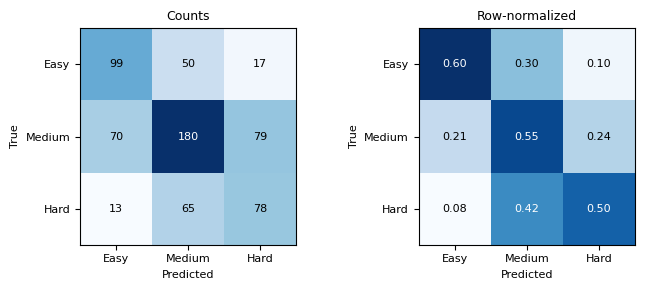

,precision,recall,f1,support
Easy,0.544,0.596,0.569,166
Medium,0.610,0.547,0.577,329
Hard,0.448,0.500,0.473,156


In [9]:
best_new = new.sort_values('cv_macro_f1_mean', ascending=False).iloc[0]
P_best = np.load(os.path.join(PROBA_DIR, f"{REP}_{best_new['model']}_test.npy"))
pred_best = P_best.argmax(axis=1)

cm = confusion_matrix(yte, pred_best, labels=[0, 1, 2])
cm_norm = cm / cm.sum(axis=1, keepdims=True)
pd.DataFrame(cm, index=[f'true_{c}' for c in CLASS_NAMES], columns=[f'pred_{c}' for c in CLASS_NAMES]
             ).to_csv(os.path.join(TAB_DIR, 'difficulty_tfidf_digits_confusion.csv'))

errors = cm.sum() - np.trace(cm)
far = cm[0, 2] + cm[2, 0]
print('Model:', f"{REP} x {best_new['model']}")
print(cm)
print('Proporsi kesalahan Easy<->Hard :', round(far / errors * 100, 1), '%')
print('Distribusi prediksi:', dict(zip(CLASS_NAMES, np.bincount(pred_best, minlength=3))),
      '| asli:', dict(zip(CLASS_NAMES, np.bincount(yte, minlength=3))))

fig, axes = plt.subplots(1, 2, figsize=(7, 3))
for ax, mat, title, fmt in [(axes[0], cm, 'Counts', '{:d}'), (axes[1], cm_norm, 'Row-normalized', '{:.2f}')]:
    ax.imshow(mat, cmap='Blues')
    ax.set_xticks(range(3)); ax.set_xticklabels(CLASS_NAMES, fontsize=8)
    ax.set_yticks(range(3)); ax.set_yticklabels(CLASS_NAMES, fontsize=8)
    ax.set_xlabel('Predicted', fontsize=8); ax.set_ylabel('True', fontsize=8)
    ax.set_title(title, fontsize=9)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, fmt.format(mat[i, j]), ha='center', va='center', fontsize=8,
                    color='white' if mat[i, j] > mat.max() * 0.6 else 'black')
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'difficulty_tfidf_digits_confusion.png'), dpi=300, bbox_inches='tight')
plt.show()

prec, rec, f1c, sup = precision_recall_fscore_support(yte, pred_best, labels=[0, 1, 2], zero_division=0)
per_class = pd.DataFrame({'precision': prec, 'recall': rec, 'f1': f1c, 'support': sup}, index=CLASS_NAMES).round(3)
per_class.to_csv(os.path.join(TAB_DIR, 'difficulty_tfidf_digits_per_class.csv'))
per_class

## Cara memakai hasil ini di paper

- Jadikan **`tfidf_digits` baris tambahan di Tabel IV-A**, berlabel jelas (representasi ke-6, hanya untuk difficulty), dan jelaskan alasannya: Notebook 07 menunjukkan angka membawa informasi difficulty yang dibuang pada pembersihan standar.
- Tentukan **"model terbaik untuk difficulty" dari tabel gabungan menurut CV**, bukan dari test.
- Bandingkan dengan model terbaik Notebook 05 lewat **selisih berpasangan**, bukan dengan melihat dua angka. Jika interval selisih memuat 0, tulis bahwa keduanya setara.
- Jika `tfidf_digits` unggul atas CodeBERT/bge, simpulkan dengan hati-hati: yang berperan adalah **informasi angka**, bukan jenis representasi. Catat bahwa transformer juga melihat angka (view ringan), jadi keunggulan TF-IDF berarti model kontekstual tidak memanfaatkannya lebih baik, bukan bahwa mereka tidak melihatnya.
- Keterbatasan: token angka mencakup angka di contoh input/output, bukan hanya batasan.